# An experimental five-term specification

The production model carries three Facebook terms — the women's audience share, the men's, and
their ratio. `14_specification_stability.ipynb` found that the two **level** terms
(`fb_18_999_men`, `fb_18_999_wom`) flip sign depending on which controls are present, in every
outcome they appear in, while the **ratio** term `fb_18_999_r` does not (D39). The obvious
follow-up is what this notebook does: keep only the Facebook term that behaved, and see what it
costs.

```
{indicator}_{outcome} ~ fb_18_999_r + hdi + gdi + gdp_pcap + year
```

Two questions, in order:

1. **What does it cost in fit?** In-sample R², leave-one-country-out R², and LOCO MAE, against the
   production seven-term specification on the same rows.
2. **Is what is left stable?** The same `robustipy` sweep as notebook 14, now over five focal
   variables and 2⁴ = 16 control combinations each.

**This is an exploration.** It fits nothing into production, promotes nothing, and writes only to
its own output folders. Decisions taken here are recorded in `doc/decisions_exploration.md`.

In [1]:
import itertools
import re
import sys
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from robustipy.models import OLSRobust

# put src/ on the path — this notebook lives in src/analysis_notebooks/
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'params.py').exists())
sys.path.insert(0, str(SRC))

import model_performance as mp   # loco() and pooled_r2() — the same code 02 reports from
import params
import plotting as plot
plot.STYLE = dict(plot.STYLE); plot.STYLE['save'] = True

warnings.filterwarnings('ignore')

NOTEBOOK = '15_experimental_model_design'
CFG = params.FINAL_MODEL
PROD_SPEC = CFG['spec']
EXP_SPEC = ['fb_18_999_r', 'hdi', 'gdi', 'gdp_pcap', 'year']
MODELS = {'production (7)': PROD_SPEC, 'experimental (5)': EXP_SPEC}
OUTCOMES = CFG['outcome_vars']          # ['ggi', 'wom', 'men']

# robustipy settings, identical to notebook 14 so the two sweeps are comparable
DRAWS, KFOLD = 100, 5
OOS_METRIC, N_CPU = 'pseudo-r2', 4

print('production  :', ' + '.join(PROD_SPEC))
print('experimental:', ' + '.join(EXP_SPEC))
print('dropped     :', ' + '.join(v for v in PROD_SPEC if v not in EXP_SPEC))
print(f'stability sweep: {len(EXP_SPEC)} focal vars x '
      f'{2 ** (len(EXP_SPEC) - 1)} control combinations each')

production  : fb_18_999_men + fb_18_999_wom + fb_18_999_r + hdi + gdi + gdp_pcap + year
experimental: fb_18_999_r + hdi + gdi + gdp_pcap + year
dropped     : fb_18_999_men + fb_18_999_wom
stability sweep: 5 focal vars x 16 control combinations each


## 1. The panel

The **unrefreshed** survey panel — the production file, exactly as notebooks 01, 02 and 14 read
it: 108 internet rows and 99 mobile rows. Notebook 13's extended panel (+17 surveys per indicator)
is deliberately *not* used here. Changing the specification and the sample at the same time would
leave neither change readable, and D39 already showed the added rows carry stale offline
predictors.

Both specifications are complete on every row of the panel, so they are scored on identical
samples and their R² are directly comparable.

In [2]:
def load(indicator):
    """the production panel for one indicator, `year` centred on FINAL_MODEL['year_origin']"""
    data = pd.read_csv(params.PROCESSED / 'combined_data/updated_ground_truth_and_fb'
                       / indicator / CFG['dataset'])
    data['year'] = data[f'{indicator}_year'] - CFG['year_origin']
    return data


panels = {i: load(i) for i in CFG['indicators']}
for indicator, data in panels.items():
    targets = [f'{indicator}_{o}' for o in OUTCOMES]
    complete = {name: len(data.dropna(subset=spec + targets)) for name, spec in MODELS.items()}
    print(f'{indicator:9s} {len(data):4d} rows | complete: '
          + ' | '.join(f'{k} {v}' for k, v in complete.items())
          + f' | {data[CFG["leave_column"]].nunique()} countries')

internet   108 rows | complete: production (7) 108 | experimental (5) 108 | 95 countries
mobile      99 rows | complete: production (7) 99 | experimental (5) 99 | 83 countries


## 2. What does the fifth-term model cost?

`model_performance.loco` refits with one country held out at a time and predicts that country's
rows, so no prediction comes from a model that saw the country. LOCO R² is the project's headline
number and the one to read; in-sample R² is here only for contrast, and MAE is reported both
in-sample and out.

Two registered variants are carried as context, because the experimental spec sits between them:
`online_with_CIS` is the three Facebook terms alone, `offline_with_CIS` the four offline terms
alone. The experimental spec is the offline four plus **one** Facebook term.

In [3]:
CONTEXT_VARIANTS = ['online_with_CIS', 'offline_with_CIS']


def score(data, spec, outcome, leave_column):
    """the metric set: in-sample R2 and MAE, and the leave-one-country-out pair"""
    fit = sm.OLS(data[outcome], sm.add_constant(data[spec]), missing='drop').fit()
    y, pred = mp.loco(data, spec, outcome, leave_column)
    return {'n': int(fit.nobs), 'k': len(spec), 'spec': ' + '.join(spec),
            'r2': float(fit.rsquared), 'adj_r2': float(fit.rsquared_adj),
            'mae': float(fit.resid.abs().mean()),
            'loco_r2': mp.pooled_r2(y, pred), 'loco_mae': float((y - pred).abs().mean())}


rows = []
for indicator, data in panels.items():
    for outcome_var in OUTCOMES:
        outcome = f'{indicator}_{outcome_var}'
        candidates = dict(MODELS)
        # `_align` variants swap their Facebook term per outcome; resolve_spec handles that
        candidates.update({v: params.resolve_spec(v, outcome_var) for v in CONTEXT_VARIANTS})
        for name, spec in candidates.items():
            rows.append({'indicator': indicator, 'outcome': outcome_var, 'model': name,
                         'is_context': name in CONTEXT_VARIANTS,
                         **score(data, spec, outcome, CFG['leave_column'])})

performance = pd.DataFrame(rows)
performance[['indicator', 'outcome', 'model', 'n', 'k', 'r2', 'adj_r2', 'mae',
             'loco_r2', 'loco_mae']].round(4)

,indicator,outcome,model,n,k,r2,adj_r2,mae,loco_r2,loco_mae
0,internet,ggi,production (7),108,7,0.8281,0.8161,0.0763,0.7910,0.0841
1,internet,ggi,experimental (5),108,5,0.7652,0.7536,0.0930,0.7311,0.0997
2,internet,ggi,online_with_CIS,108,3,0.7637,0.7569,0.0881,0.7410,0.0927
3,internet,ggi,offline_with_CIS,108,4,0.7462,0.7363,0.0949,0.7187,0.1001
4,internet,wom,production (7),108,7,0.9045,0.8979,0.0770,0.8813,0.0851
5,internet,wom,experimental (5),108,5,0.8750,0.8689,0.0944,0.8539,0.1016
6,internet,wom,online_with_CIS,108,3,0.7530,0.7459,0.1249,0.7300,0.1305
7,internet,wom,offline_with_CIS,108,4,0.8749,0.8701,0.0947,0.8587,0.1004
8,internet,men,production (7),108,7,0.8732,0.8643,0.0747,0.8425,0.0824
9,internet,men,experimental (5),108,5,0.8142,0.8051,0.0992,0.7827,0.1067


In [4]:
# the experimental model against production, one row per target
wide = performance[~performance['is_context']].pivot_table(
    index=['indicator', 'outcome'], columns='model',
    values=['r2', 'loco_r2', 'loco_mae', 'mae'])
delta = (wide.xs('experimental (5)', level='model', axis=1)
         - wide.xs('production (7)', level='model', axis=1))
delta.columns = [f'd_{c}' for c in delta.columns]
comparison = (wide.xs('production (7)', level='model', axis=1)
              .add_prefix('prod_')
              .join(wide.xs('experimental (5)', level='model', axis=1).add_prefix('exp_'))
              .join(delta))
comparison = comparison[['prod_r2', 'exp_r2', 'd_r2',
                         'prod_loco_r2', 'exp_loco_r2', 'd_loco_r2',
                         'prod_loco_mae', 'exp_loco_mae', 'd_loco_mae']].reset_index()
comparison.round(4)

,indicator,outcome,prod_r2,exp_r2,d_r2,prod_loco_r2,exp_loco_r2,d_loco_r2,prod_loco_mae,exp_loco_mae,d_loco_mae
0,internet,ggi,0.8281,0.7652,-0.0630,0.7910,0.7311,-0.0599,0.0841,0.0997,0.0156
1,internet,men,0.8732,0.8142,-0.0590,0.8425,0.7827,-0.0599,0.0824,0.1067,0.0243
2,internet,wom,0.9045,0.8750,-0.0295,0.8813,0.8539,-0.0274,0.0851,0.1016,0.0165
3,mobile,ggi,0.7393,0.6743,-0.0650,0.6827,0.6214,-0.0613,0.0652,0.0764,0.0112
4,mobile,men,0.6343,0.4752,-0.1591,0.5626,0.3852,-0.1774,0.0763,0.0948,0.0185
5,mobile,wom,0.7959,0.6746,-0.1213,0.7489,0.6134,-0.1355,0.0829,0.1093,0.0264


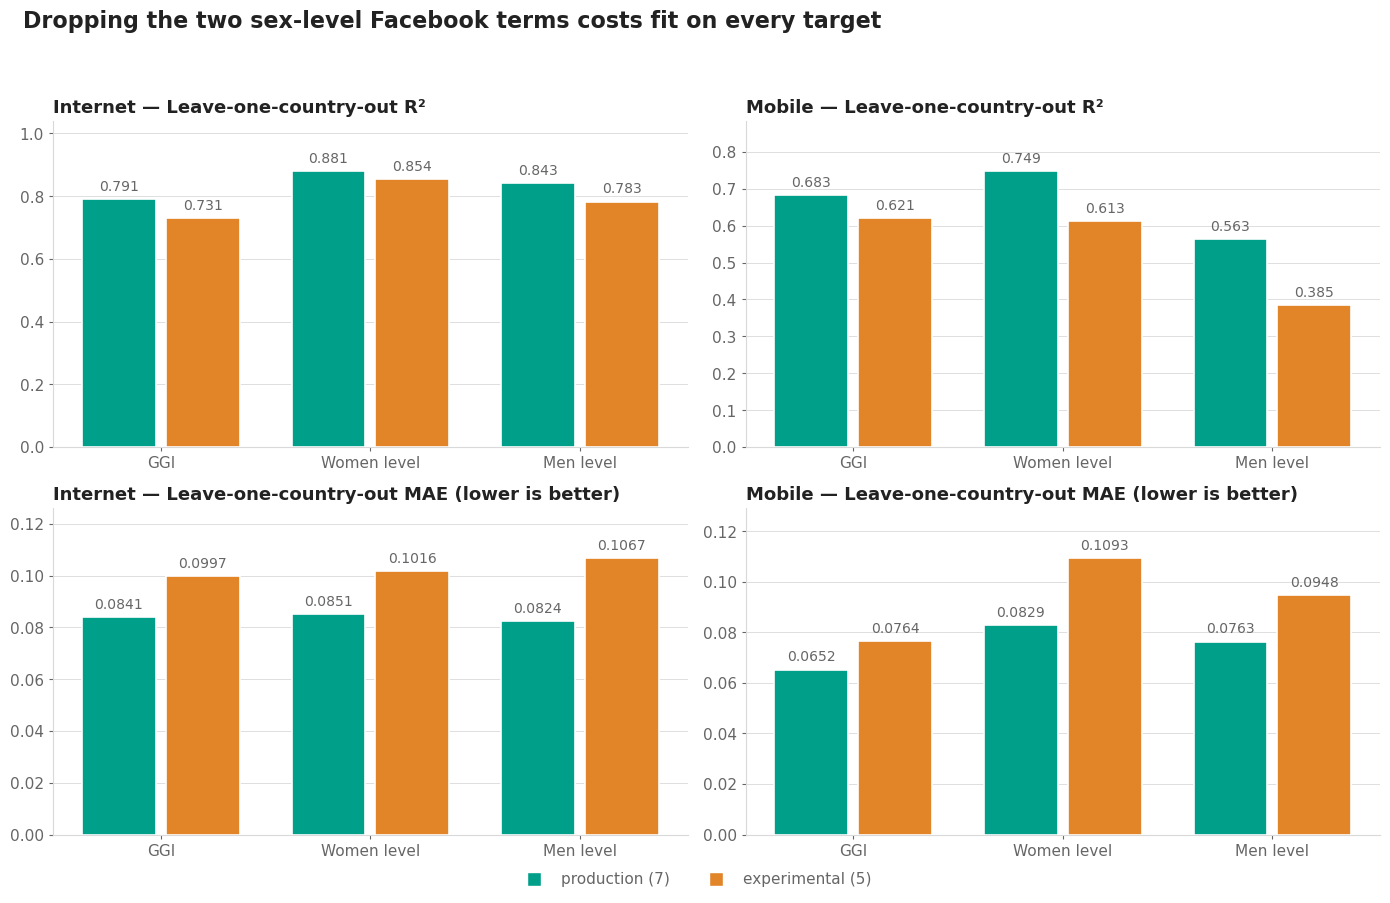

In [5]:
BAR_METRICS = [('loco_r2', 'Leave-one-country-out R²', '{:.3f}'),
               ('loco_mae', 'Leave-one-country-out MAE (lower is better)', '{:.4f}')]
LABELS = {'ggi': 'GGI', 'wom': 'Women level', 'men': 'Men level'}
SERIES = list(MODELS)
COLOURS = {'production (7)': plot.PALETTE[0], 'experimental (5)': plot.PALETTE[1]}

fig, axes = plt.subplots(len(BAR_METRICS), len(CFG['indicators']), figsize=(14, 9))
for row, (metric, metric_label, fmt) in enumerate(BAR_METRICS):
    for col, indicator in enumerate(CFG['indicators']):
        ax = axes[row, col]
        block = performance[(performance['indicator'] == indicator)
                            & (~performance['is_context'])]
        table = block.pivot_table(index='outcome', columns='model', values=metric).reindex(OUTCOMES)
        plot.grouped_bars(ax, [LABELS[o] for o in OUTCOMES], SERIES,
                          {s: table[s].to_numpy() for s in SERIES}, colours=COLOURS, fmt=fmt)
        plot.tidy(ax, title=f'{indicator.capitalize()} — {metric_label}', grid='y')
        # headroom for the value labels
        top = table.to_numpy().max()
        ax.set_ylim(0, top * 1.18)

plot.legend(fig, [plot.swatch(COLOURS[s], s) for s in SERIES], y=-0.01)
plot.suptitle(fig, 'Dropping the two sex-level Facebook terms costs fit on every target')
fig.tight_layout(rect=(0, 0.02, 1, 0.94))
plot.save(fig, NOTEBOOK, 'performance_comparison')
plt.show()

## 3. What happens to the coefficients that survive?

Five terms are common to both specifications. If the two sex-level Facebook terms were mostly
soaking up collinearity, the shared coefficients should move a lot when they leave; if they were
carrying independent signal, the shared coefficients should stay put and the fit should fall.

In [6]:
rows = []
for indicator, data in panels.items():
    for outcome_var in OUTCOMES:
        outcome = f'{indicator}_{outcome_var}'
        fits = {name: sm.OLS(data[outcome], sm.add_constant(data[spec]), missing='drop').fit()
                for name, spec in MODELS.items()}
        for term in EXP_SPEC:
            production, experimental = fits['production (7)'], fits['experimental (5)']
            rows.append({
                'indicator': indicator, 'outcome': outcome_var, 'term': term,
                'production_coef': float(production.params[term]),
                'production_p': float(production.pvalues[term]),
                'experimental_coef': float(experimental.params[term]),
                'experimental_p': float(experimental.pvalues[term]),
                'change': float(experimental.params[term] - production.params[term]),
                'sign_flips': bool(np.sign(production.params[term])
                                   != np.sign(experimental.params[term])),
            })

coefficients = pd.DataFrame(rows)
print(f"sign flips between the two specifications: {int(coefficients['sign_flips'].sum())} "
      f'of {len(coefficients)} shared coefficients')
coefficients.round(4)

sign flips between the two specifications: 3 of 30 shared coefficients


,indicator,outcome,term,production_coef,production_p,experimental_coef,experimental_p,change,sign_flips
0,internet,ggi,fb_18_999_r,0.5062,0.0000,0.2786,0.0050,-0.2276,False
1,internet,ggi,hdi,0.2592,0.2927,0.6772,0.0143,0.4180,False
2,internet,ggi,gdi,1.3733,0.0000,1.2807,0.0006,-0.0926,False
3,internet,ggi,gdp_pcap,0.0049,0.8446,-0.0280,0.3161,-0.0328,True
4,internet,ggi,year,0.0092,0.1157,0.0103,0.1262,0.0011,False
5,internet,wom,fb_18_999_r,0.1226,0.2542,0.0313,0.7448,-0.0913,False
6,internet,wom,hdi,0.8636,0.0007,1.2520,0.0000,0.3884,False
7,internet,wom,gdi,1.0564,0.0013,1.0264,0.0051,-0.0300,False
8,internet,wom,gdp_pcap,0.0355,0.1583,0.0136,0.6208,-0.0219,False
9,internet,wom,year,0.0198,0.0010,0.0203,0.0027,0.0005,False


## 4. Specification stability of the five terms

The same sweep as notebook 14, on the experimental spec: each variable in turn as the focal X,
refitted across every combination of the other four as controls — 2⁴ = 16 specifications per focal
variable, 30 runs in all.

The comparison to keep in view: in notebook 14 only 22 of 42 focal-variable runs kept their sign
across all 64 control sets. A five-term spec has fewer ways to go wrong, so a higher share is
expected mechanically — what matters is whether `fb_18_999_r` is stable now that it is the only
Facebook term, and whether the offline terms behave as they did in the seven-term sweep.

In [7]:
def stability(data, outcome, focal, controls):
    """robustipy over every subset of `controls`, with `focal` as the estimand"""
    frame = data.dropna(subset=EXP_SPEC + [outcome])
    model = OLSRobust(y=[outcome], x=[focal], data=frame)
    # every argument is passed explicitly: robustipy prompts interactively for any it is not
    # given, which hangs a non-interactive run
    model.fit(controls=controls, draws=DRAWS, kfold=KFOLD, oos_metric=OOS_METRIC,
              seed=params.SEED, n_cpu=N_CPU, compute_shap=False)
    return model.get_results().summary_df


records, curves = [], []

for indicator, data in panels.items():
    for outcome_var in OUTCOMES:
        outcome = f'{indicator}_{outcome_var}'
        # the coefficient the experimental model itself reports, for reference
        full = sm.OLS(data[outcome], sm.add_constant(data[EXP_SPEC]), missing='drop').fit()

        for focal in EXP_SPEC:
            summary = stability(data, outcome, focal, [c for c in EXP_SPEC if c != focal])
            median = summary['median']

            records.append({
                'indicator': indicator, 'outcome': outcome_var, 'focal': focal,
                'n_specs': len(summary),
                'experimental_coef': float(full.params[focal]),
                'experimental_p': float(full.pvalues[focal]),
                'median_coef': float(median.median()),
                'min_coef': float(summary['min'].min()),
                'max_coef': float(summary['max'].max()),
                'share_positive': float((median > 0).mean()),
                'sign_stable': bool((median > 0).all() or (median < 0).all()),
                'share_ci_excludes_0': float(((summary['ci_down'] > 0)
                                              | (summary['ci_up'] < 0)).mean()),
                'median_r2': float(summary['r2'].median()),
                'median_oos': float(summary['av_k_metric'].median()),
            })
            curves.append(summary.assign(indicator=indicator, outcome=outcome_var, focal=focal))
            print(f'  {indicator:9s} {outcome_var:4s} {focal:16s} '
                  f'median {median.median():+.4f}  sign stable: {records[-1]["sign_stable"]}')

stability_summary = pd.DataFrame(records)
curve_data = pd.concat(curves, ignore_index=True)
print(f'\n{len(stability_summary)} focal-variable runs, {len(curve_data)} specifications total')
print(f"sign stable: {int(stability_summary['sign_stable'].sum())} of {len(stability_summary)}")

OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is fb_18_999_r. Let's begin the calculations...
Total model runs: 1,600 (draws=100, control_specs=16, y_composites=1)


Bootstrap draws:   0.0%|          | 0/1600 [00:00<?, ?draw/s]

  internet  ggi  fb_18_999_r      median +0.4587  sign stable: True
OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is hdi. Let's begin the calculations...
Total model runs: 1,600 (draws=100, control_specs=16, y_composites=1)


Bootstrap draws:   0.0%|          | 0/1600 [00:00<?, ?draw/s]

  internet  ggi  hdi              median +0.6770  sign stable: True
OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is gdi. Let's begin the calculations...
Total model runs: 1,600 (draws=100, control_specs=16, y_composites=1)


...

  mobile    men  gdi              median -0.5685  sign stable: False
OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is gdp_pcap. Let's begin the calculations...
Total model runs: 1,600 (draws=100, control_specs=16, y_composites=1)


Bootstrap draws:   0.0%|          | 0/1600 [00:00<?, ?draw/s]

  mobile    men  gdp_pcap         median +0.0757  sign stable: True
OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is year. Let's begin the calculations...
Total model runs: 1,600 (draws=100, control_specs=16, y_composites=1)


Bootstrap draws:   0.0%|          | 0/1600 [00:00<?, ?draw/s]

  mobile    men  year             median +0.0091  sign stable: True

30 focal-variable runs, 480 specifications total
sign stable: 22 of 30


In [8]:
stability_summary[['indicator', 'outcome', 'focal', 'experimental_coef', 'median_coef',
                   'min_coef', 'max_coef', 'sign_stable', 'share_positive',
                   'share_ci_excludes_0']].round(4)

,indicator,outcome,focal,experimental_coef,median_coef,min_coef,max_coef,sign_stable,share_positive,share_ci_excludes_0
0,internet,ggi,fb_18_999_r,0.2786,0.4587,-0.0539,0.8839,True,1.0000,1.0000
1,internet,ggi,hdi,0.6772,0.6770,-0.1294,2.1738,True,1.0000,1.0000
2,internet,ggi,gdi,1.2807,1.7772,0.3131,4.1552,True,1.0000,1.0000
3,internet,ggi,gdp_pcap,-0.0280,0.0157,-0.1277,0.1432,False,0.5625,0.5625
4,internet,ggi,year,0.0103,0.0137,-0.0123,0.0799,True,1.0000,0.3750
5,internet,wom,fb_18_999_r,0.0313,0.2165,-0.2944,1.1495,True,1.0000,0.4375
6,internet,wom,hdi,1.2520,1.5160,0.4612,2.4308,True,1.0000,1.0000
7,internet,wom,gdi,1.0264,1.4086,-0.4567,5.3535,True,1.0000,0.9375
8,internet,wom,gdp_pcap,0.0136,0.0755,-0.0869,0.2048,False,0.8125,0.5000
9,internet,wom,year,0.0203,0.0213,-0.0011,0.1155,True,1.0000,1.0000


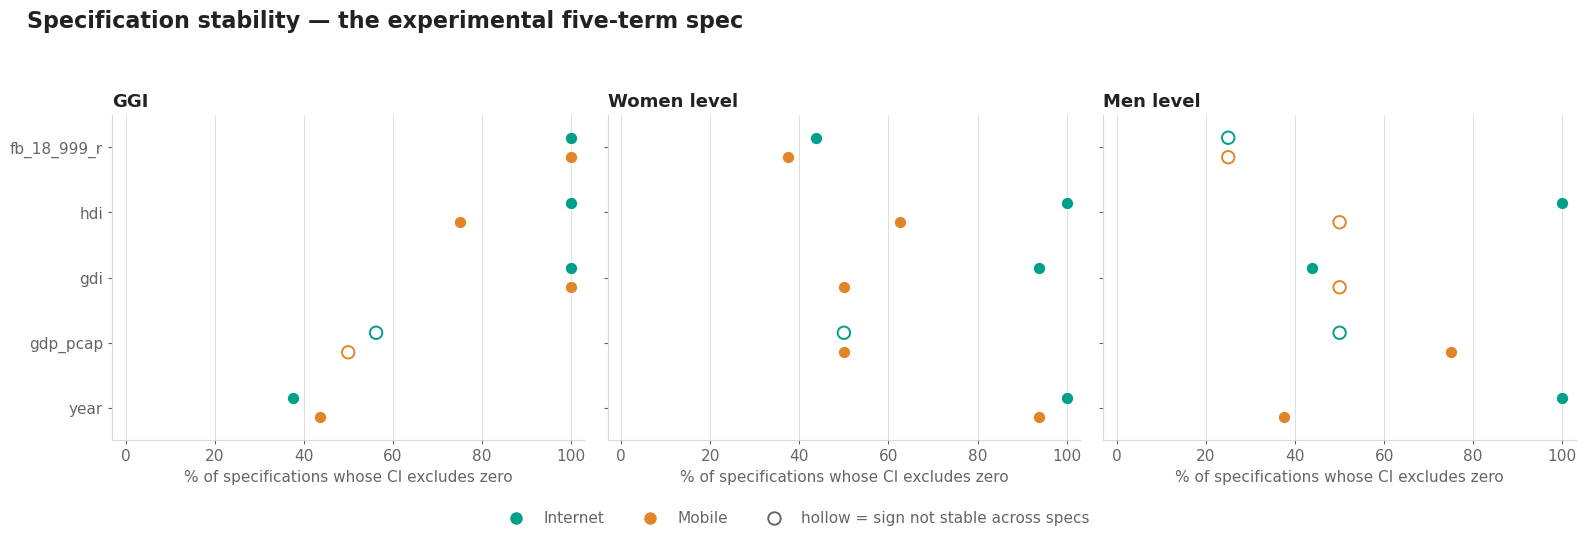

In [9]:
fig, axes = plt.subplots(1, len(OUTCOMES), figsize=(16, 5), sharey=True)

for ax, outcome_var in zip(np.atleast_1d(axes), OUTCOMES):
    block = stability_summary[stability_summary['outcome'] == outcome_var]
    y = np.arange(len(EXP_SPEC))
    for k, indicator in enumerate(CFG['indicators']):
        sub = block[block['indicator'] == indicator].set_index('focal').reindex(EXP_SPEC)
        offset = (k - 0.5) * 0.3
        # a hollow marker where the sign is not stable: the value is there, the claim is not
        for i, (_, r) in enumerate(sub.iterrows()):
            filled = bool(r['sign_stable'])
            ax.scatter(r['share_ci_excludes_0'] * 100, y[i] + offset, s=80,
                       facecolor=plot.PALETTE[k] if filled else 'none',
                       edgecolor=plot.PALETTE[k] if not filled else 'white',
                       linewidth=1.4 if not filled else 0.8, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(EXP_SPEC)
    ax.set_ylim(len(EXP_SPEC) - 0.5, -0.5)
    ax.set_xlim(-3, 103)
    plot.tidy(ax, title=LABELS[outcome_var],
              xlabel='% of specifications whose CI excludes zero', grid='x')

handles = [plot.swatch(plot.PALETTE[k], i.capitalize(), marker='o')
           for k, i in enumerate(CFG['indicators'])]
handles.append(plt.Line2D([], [], marker='o', linestyle='None', markersize=9,
                          markerfacecolor='none', markeredgecolor=plot.MUTED,
                          markeredgewidth=1.4, label='hollow = sign not stable across specs'))
plot.legend(fig, handles, y=-0.08)
plot.suptitle(fig, 'Specification stability — the experimental five-term spec')
fig.tight_layout(rect=(0, 0, 1, 0.92))
plot.save(fig, NOTEBOOK, 'specification_stability')
plt.show()

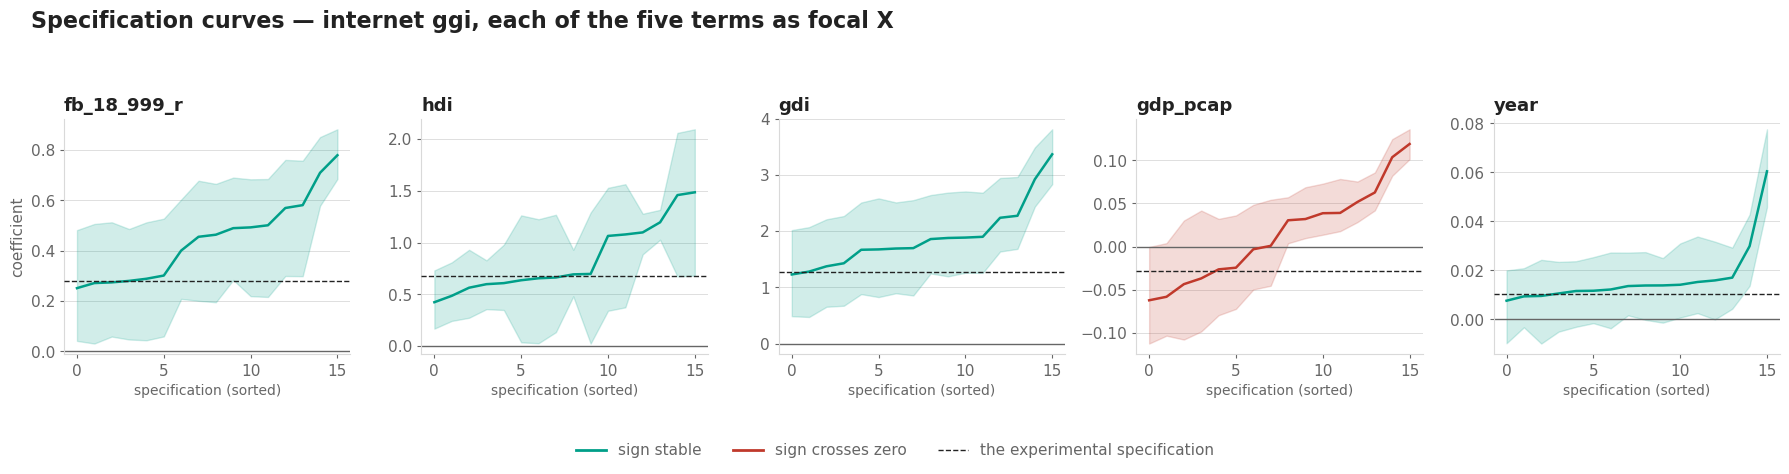

In [10]:
INDICATOR, OUTCOME_VAR = 'internet', 'ggi'   # change to redraw for another target

block = curve_data[(curve_data['indicator'] == INDICATOR)
                   & (curve_data['outcome'] == OUTCOME_VAR)]
reference = stability_summary[(stability_summary['indicator'] == INDICATOR)
                              & (stability_summary['outcome'] == OUTCOME_VAR)].set_index('focal')

fig, axes = plt.subplots(1, len(EXP_SPEC), figsize=(18, 4.2))
for ax, focal in zip(axes.ravel(), EXP_SPEC):
    sub = block[block['focal'] == focal].sort_values('median').reset_index(drop=True)
    x = np.arange(len(sub))
    crosses = (sub['median'] > 0).any() and (sub['median'] < 0).any()
    colour = plot.PALETTE[0] if not crosses else plot.FLAG

    ax.fill_between(x, sub['ci_down'], sub['ci_up'], color=colour, alpha=0.18, zorder=1)
    ax.plot(x, sub['median'], color=colour, linewidth=1.8, zorder=3)
    ax.axhline(0, color=plot.MUTED, linewidth=1, zorder=2)
    ax.axhline(reference.loc[focal, 'experimental_coef'], color=plot.INK, linewidth=1,
               linestyle='--', zorder=4)
    plot.tidy(ax, title=focal, grid='y')
    ax.set_xlabel('specification (sorted)', fontsize=plot.STYLE['tick_fs'] - 1, color=plot.MUTED)

axes[0].set_ylabel('coefficient', fontsize=plot.STYLE['tick_fs'], color=plot.MUTED)
plot.legend(fig, [plt.Line2D([], [], color=plot.PALETTE[0], linewidth=2, label='sign stable'),
                  plt.Line2D([], [], color=plot.FLAG, linewidth=2, label='sign crosses zero'),
                  plt.Line2D([], [], color=plot.INK, linewidth=1, linestyle='--',
                             label='the experimental specification')], y=-0.12)
plot.suptitle(fig, f'Specification curves — {INDICATOR} {OUTCOME_VAR}, '
                   'each of the five terms as focal X')
fig.tight_layout(rect=(0, 0.02, 1, 0.90))
plot.save(fig, NOTEBOOK, f'specification_curves_{INDICATOR}_{OUTCOME_VAR}')
plt.show()

## 5. How far can the fit move within the five terms?

The mirror of notebook 14 §5, on the smaller spec: every non-empty subset of the five terms is
2⁵ − 1 = **31 specifications**, each scored with the project's own LOCO. It answers whether the
experimental spec is at least the best that these five terms can do, and shows the production
model's LOCO R² as the line the whole swarm has to clear.

In [11]:
def spec_fit_table(spec_vars):
    """in-sample R2, LOCO R2 and LOCO MAE for every non-empty subset of `spec_vars`"""
    rows = []
    for indicator, data in panels.items():
        for outcome_var in OUTCOMES:
            outcome = f'{indicator}_{outcome_var}'
            for size in range(1, len(spec_vars) + 1):
                for subset in itertools.combinations(spec_vars, size):
                    rows.append({
                        'indicator': indicator, 'outcome': outcome_var, 'k': size,
                        # spec order, so a subset's label is the same string everywhere
                        'spec': ' + '.join(v for v in spec_vars if v in subset),
                        **score(data, list(subset), outcome, CFG['leave_column'])})
    return pd.DataFrame(rows)


spec_fit = spec_fit_table(EXP_SPEC)
spec_fit['is_experimental'] = spec_fit['k'] == len(EXP_SPEC)
# every subset keeps the whole sample, so R2 is comparable across the 31
assert spec_fit.groupby('indicator')['n'].nunique().eq(1).all(), 'the sample moves between specs'

production_loco = (performance[performance['model'] == 'production (7)']
                   .set_index(['indicator', 'outcome'])['loco_r2'])
print(spec_fit.groupby(['indicator', 'outcome'])[['r2', 'loco_r2', 'loco_mae']]
      .agg(['min', 'median', 'max']).round(3).to_string())

                      r2               loco_r2               loco_mae              
                     min median    max     min median    max      min median    max
indicator outcome                                                                  
internet  ggi      0.281  0.723  0.765   0.254  0.699  0.734    0.099  0.105  0.170
          men      0.383  0.796  0.814   0.359  0.771  0.797    0.103  0.109  0.183
          wom      0.388  0.848  0.875   0.364  0.837  0.862    0.099  0.108  0.218
mobile    ggi      0.081  0.636  0.674   0.046  0.599  0.629    0.074  0.076  0.122
          men      0.073  0.439  0.475   0.031  0.380  0.409    0.092  0.094  0.119
          wom      0.101  0.652  0.675   0.062  0.614  0.629    0.106  0.109  0.171


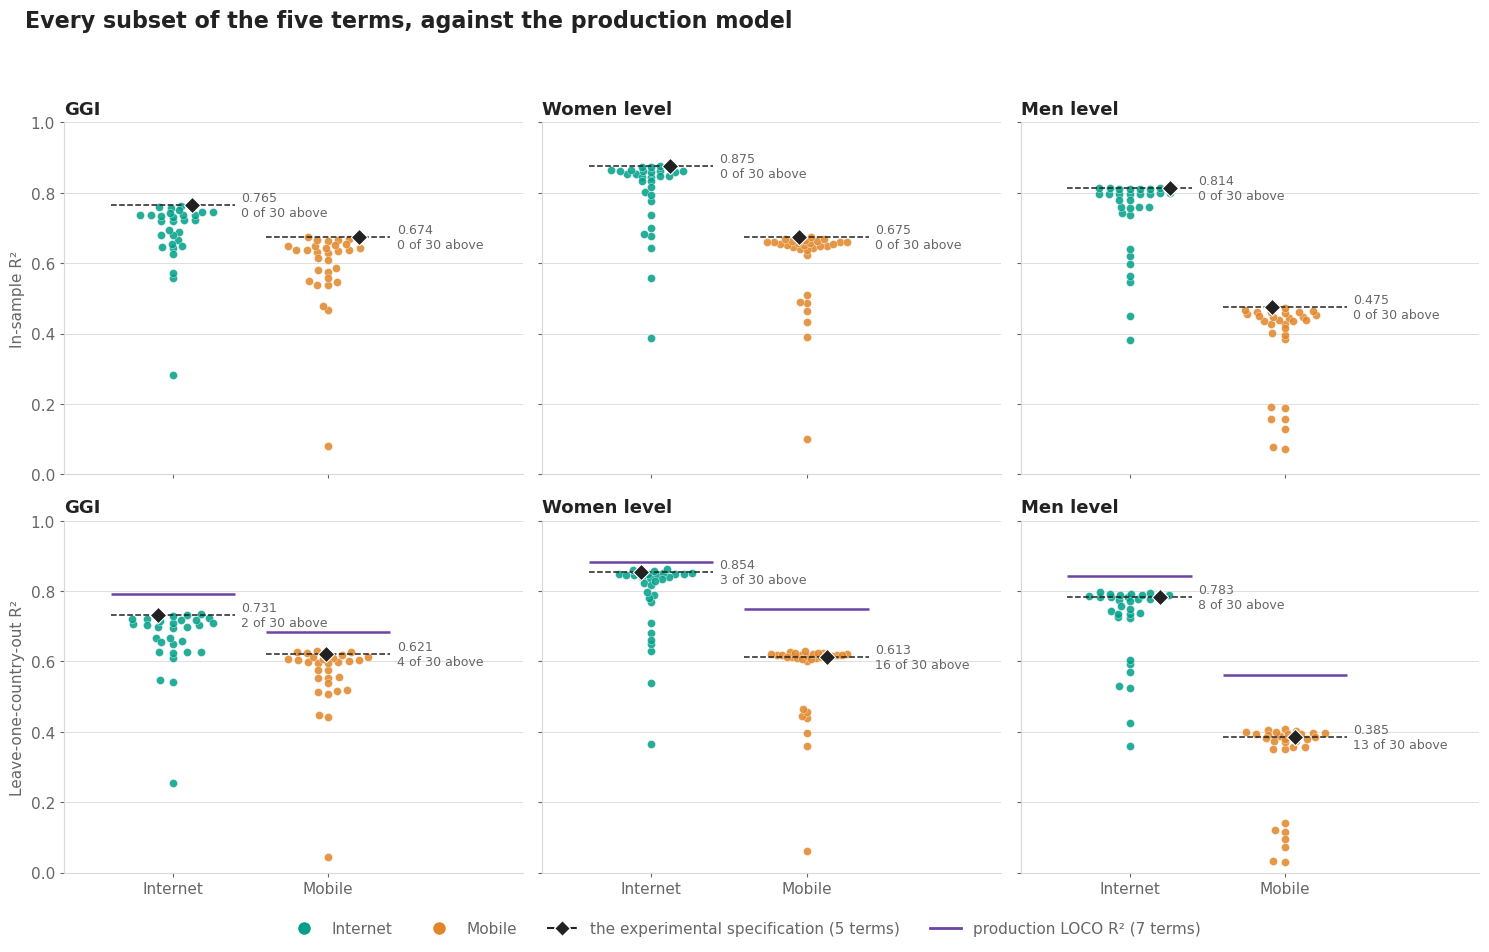

In [12]:
METRICS = [('r2', 'In-sample R²'), ('loco_r2', 'Leave-one-country-out R²')]

fig, axes = plt.subplots(len(METRICS), len(OUTCOMES), figsize=(15, 9.5), sharex=True, sharey=True)
for row, (metric, metric_label) in enumerate(METRICS):
    for col, outcome_var in enumerate(OUTCOMES):
        ax = axes[row, col]
        for k, indicator in enumerate(CFG['indicators']):
            block = spec_fit[(spec_fit['indicator'] == indicator)
                             & (spec_fit['outcome'] == outcome_var)]
            xs = plot.beeswarm(ax, block[metric].to_numpy(), centre=k, width=0.26,
                               colour=plot.PALETTE[k], size=34, alpha=0.85)
            at = block['is_experimental'].to_numpy()
            value = block[metric].to_numpy()[at][0]
            ax.hlines(value, k - 0.40, k + 0.40, color=plot.INK, linewidth=1.1,
                      linestyle='--', zorder=5)
            ax.scatter(xs[at], value, s=70, marker='D', facecolor=plot.INK,
                       edgecolor='white', linewidth=0.8, zorder=6)
            ax.annotate(f'{value:.3f}\n{int((block[metric] > value).sum())} of '
                        f'{len(block) - 1} above', (k + 0.44, value), ha='left', va='center',
                        fontsize=plot.STYLE['tick_fs'] - 2, color=plot.MUTED)
            # the production model, as the bar the five terms are trying to clear. PALETTE[2]
            # rather than plot.FLAG: this is another model, not a degenerate value
            if metric == 'loco_r2':
                ax.hlines(production_loco.loc[(indicator, outcome_var)], k - 0.40, k + 0.40,
                          color=plot.PALETTE[2], linewidth=1.8, zorder=7)
        ax.set_xlim(-0.7, 2.25)
        ax.set_ylim(0, 1)
        ax.set_xticks(range(len(CFG['indicators'])))
        ax.set_xticklabels([i.capitalize() for i in CFG['indicators']])
        plot.tidy(ax, title=LABELS[outcome_var], grid='y')
        if col == 0:
            ax.set_ylabel(metric_label, fontsize=plot.STYLE['tick_fs'], color=plot.MUTED)

handles = [plot.swatch(plot.PALETTE[k], i.capitalize(), marker='o')
           for k, i in enumerate(CFG['indicators'])]
handles += [plt.Line2D([], [], marker='D', linestyle='--', color=plot.INK, markersize=8,
                       markeredgecolor='white', label='the experimental specification (5 terms)'),
            plt.Line2D([], [], color=plot.PALETTE[2], linewidth=2,
                       label='production LOCO R² (7 terms)')]
plot.legend(fig, handles, y=-0.01)
plot.suptitle(fig, 'Every subset of the five terms, against the production model')
fig.tight_layout(rect=(0, 0.03, 1, 0.94))
plot.save(fig, NOTEBOOK, 'specification_fit_beeswarm')
plt.show()

## 6. Write the tables

In [13]:
stamp = f'{datetime.now():%Y%m%d}'
for name, frame in [('experimental_performance', performance),
                    ('experimental_vs_production', comparison),
                    ('experimental_coefficients', coefficients),
                    ('experimental_specification_stability', stability_summary),
                    ('experimental_specification_curves', curve_data),
                    ('experimental_specification_fit', spec_fit)]:
    path = params.table_dir(NOTEBOOK) / f'{name}_{stamp}.csv'
    frame.to_csv(path, index=False)
    print(f'{path.name:52s} {len(frame):6d} rows')

experimental_performance_20260819.csv                    24 rows
experimental_vs_production_20260819.csv                   6 rows
experimental_coefficients_20260819.csv                   30 rows
experimental_specification_stability_20260819.csv        30 rows
experimental_specification_curves_20260819.csv          480 rows
experimental_specification_fit_20260819.csv             186 rows


## Notes

- **Nothing here is a proposal.** The five-term spec is a diagnostic: it isolates what the two
  sex-level Facebook terms contribute, by removing them. Read section 2 before reading section 4 —
  a specification can be perfectly stable and still predict worse.
- **The sample is deliberately the unrefreshed one** (108 / 99). Notebook 13's extended panel and
  the refreshed offline predictors (D40, D41) are separate changes; combining them with this one
  would make the result unattributable.
- For the **GGI** outcome the experimental spec is exactly `params.MODEL_VARIANTS`'
  `combined_with_CIS_align` — offline four plus `fb_18_999_r`. For the **level** outcomes it is
  not: the `_align` variant swaps the ratio for the matching sex's audience share, while this spec
  keeps the ratio for all three outcomes. So the GGI rows here can be checked against
  `02_model_performance.ipynb`'s `combined_with_CIS_align` rows; the level rows cannot.
- `robustipy` bootstraps within each specification (`DRAWS`) and scores out-of-sample by k-fold
  (`KFOLD`), so its `av_k_metric` is **not** the leave-one-country-out metric used in sections 2
  and 5 — k-fold holds out random rows, LOCO holds out a country. The two are never compared here.
- Decisions taken in this notebook are recorded in `doc/decisions_exploration.md`.